In [1426]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pylab import rcParams
rcParams['figure.figsize']=8,6

import warnings
warnings.filterwarnings('ignore')

In [1427]:
data=pd.read_csv('titanic_dataset.csv')

In [1428]:
data

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [1429]:
data.shape

(891, 12)

In [1430]:
data['Sex'].value_counts()

male      577
female    314
Name: Sex, dtype: int64

In [1431]:
data.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [1432]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [1433]:
data['Age'].isnull().value_counts()
# here 177 values are null either we remove above rows or we replace with mean or mode or median

False    714
True     177
Name: Age, dtype: int64

In [1434]:
data['Cabin'].isnull().value_counts()

True     687
False    204
Name: Cabin, dtype: int64

In [1435]:
# let's drop the Cabin feature as we don't have many non null values so
data.drop('Cabin',inplace=True,axis=1)

In [1436]:
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [1437]:
data.shape

(891, 11)

In [1438]:
data.describe(include='object')

,Name,Sex,Ticket,Embarked
count,891,891,891,889
unique,891,2,681,3
top,"Braund, Mr. Owen Harris",male,347082,S
freq,1,577,7,644


In [1439]:
data.isnull().sum().sort_values(ascending=True)

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         2
Age            177
dtype: int64

In [1440]:
data.isnull().sum().sort_values(ascending=True)/len(data)*100

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Embarked        0.224467
Age            19.865320
dtype: float64

In [1441]:
sns.displot(x='Age',data=data)

In [1442]:
data['Age'].mean()

29.69911764705882

In [1443]:
data['Age'].mode()

0    24.0
Name: Age, dtype: float64

In [1444]:
data['Age']=data['Age'].fillna(data['Age'].mean())

In [1445]:
data['Embarked'].head()

0    S
1    C
2    S
3    S
4    S
Name: Embarked, dtype: object

In [1446]:
data['Embarked'].value_counts()

S    644
C    168
Q     77
Name: Embarked, dtype: int64

In [1447]:
data.shape

(891, 11)

In [1448]:
data.dropna(inplace=True)

In [1449]:
data.shape

(889, 11)

In [1450]:
data.isnull().sum().sort_values(ascending=True)

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [1451]:
data.nunique()

PassengerId    889
Survived         2
Pclass           3
Name           889
Sex              2
Age             89
SibSp            7
Parch            7
Ticket         680
Fare           247
Embarked         3
dtype: int64

In [1452]:
data.Embarked.unique()

array(['S', 'C', 'Q'], dtype=object)

In [1453]:
data.Pclass.unique()

array([3, 1, 2], dtype=int64)

In [1454]:
data['Parch'].value_counts()

0    676
1    118
2     80
5      5
3      5
4      4
6      1
Name: Parch, dtype: int64

In [1455]:
numerical_cols=data.select_dtypes(include=np.number)
# numerical_cols=data.select_dtypes(include='object').columns
# numerical_cols

numerical_cols.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')

In [1456]:
for i in numerical_cols.columns:
    print(data[i].value_counts())
    print('=================================================')

1      1
599    1
588    1
589    1
590    1
      ..
302    1
303    1
304    1
305    1
891    1
Name: PassengerId, Length: 889, dtype: int64
0    549
1    340
Name: Survived, dtype: int64
3    491
1    214
2    184
Name: Pclass, dtype: int64
29.699118    177
24.000000     30
22.000000     27
18.000000     26
28.000000     25
            ... 
36.500000      1
55.500000      1
0.920000       1
23.500000      1
74.000000      1
Name: Age, Length: 89, dtype: int64
0    606
1    209
2     28
4     18
3     16
8      7
5      5
Name: SibSp, dtype: int64
0    676
1    118
2     80
5      5
3      5
4      4
6      1
Name: Parch, dtype: int64
8.0500     43
13.0000    42
7.8958     38
7.7500     34
26.0000    31
           ..
35.0000     1
28.5000     1
6.2375      1
14.0000     1
10.5167     1
Name: Fare, Length: 247, dtype: int64


In [1457]:
categorical_cols=data.select_dtypes(include='object')
# numerical_cols=data.select_dtypes(include='object').columns
# numerical_cols

categorical_cols.columns

Index(['Name', 'Sex', 'Ticket', 'Embarked'], dtype='object')

In [1458]:
for i in categorical_cols.columns:
    print(data[i].value_counts())
    print('=================================================')

Braund, Mr. Owen Harris              1
Boulos, Mr. Hanna                    1
Frolicher-Stehli, Mr. Maxmillian     1
Gilinski, Mr. Eliezer                1
Murdlin, Mr. Joseph                  1
                                    ..
McCoy, Mr. Bernard                   1
Johnson, Mr. William Cahoone Jr      1
Keane, Miss. Nora A                  1
Williams, Mr. Howard Hugh "Harry"    1
Dooley, Mr. Patrick                  1
Name: Name, Length: 889, dtype: int64
male      577
female    312
Name: Sex, dtype: int64
347082      7
CA. 2343    7
1601        7
3101295     6
CA 2144     6
           ..
9234        1
19988       1
2693        1
PC 17612    1
370376      1
Name: Ticket, Length: 680, dtype: int64
S    644
C    168
Q     77
Name: Embarked, dtype: int64


In [1459]:
def basicInfo(df_feature):
    print("Description")
    print(df_feature.describe())
    
    print("Info")
    print(df_feature.info())
    
    print("Missing value in data")
    print(df_feature.isnull().sum()/len(df_feature))
    
    print("Missing value in data in %")
    print(df_feature.isnull().sum()/len(df_feature)*100)
    
    print('=====================================================')

In [1460]:
for i in data:
    basicInfo(data[i])

Description
count    889.000000
mean     446.000000
std      256.998173
min        1.000000
25%      224.000000
50%      446.000000
75%      668.000000
max      891.000000
Name: PassengerId, dtype: float64
Info
<class 'pandas.core.series.Series'>
Int64Index: 889 entries, 0 to 890
Series name: PassengerId
Non-Null Count  Dtype
--------------  -----
889 non-null    int64
dtypes: int64(1)
memory usage: 13.9 KB
None
Missing value in data
0.0
Missing value in data in %
0.0
Description
count    889.000000
mean       0.382452
std        0.486260
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max        1.000000
Name: Survived, dtype: float64
Info
<class 'pandas.core.series.Series'>
Int64Index: 889 entries, 0 to 890
Series name: Survived
Non-Null Count  Dtype
--------------  -----
889 non-null    int64
dtypes: int64(1)
memory usage: 13.9 KB
None
Missing value in data
0.0
Missing value in data in %
0.0
Description
count    889.000000
mean       2.311586
std     

In [1461]:
data.duplicated().sum()

0

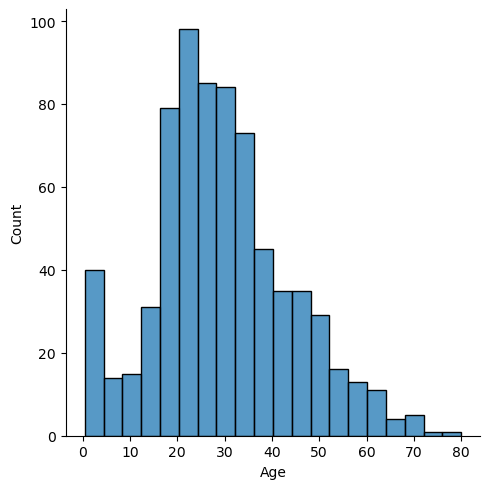

In [1462]:
# sns.boxplot(data)
plt.show()

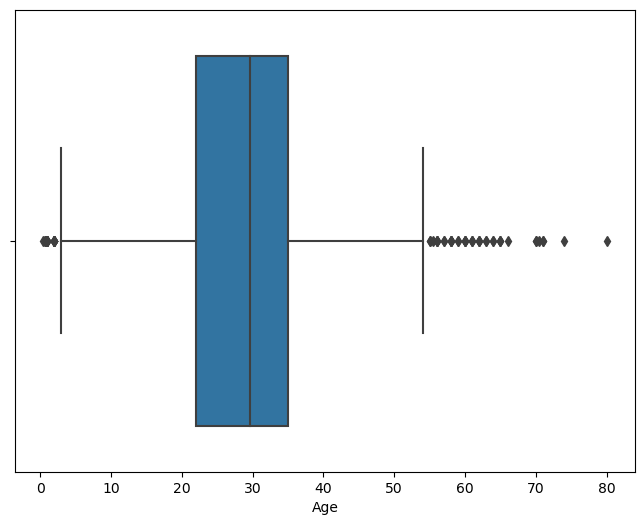

In [1463]:
sns.boxplot(data['Age'])
# plt.grid()
plt.show()

In [1464]:
type(data.head())

pandas.core.frame.DataFrame

# Removing outliers 

In [1465]:
data[data['Age']>55]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
11,12,1,1,"Bonnell, Miss. Elizabeth",female,58.0,0,0,113783,26.5500,S
33,34,0,2,"Wheadon, Mr. Edward H",male,66.0,0,0,C.A. 24579,10.5000,S
54,55,0,1,"Ostby, Mr. Engelhart Cornelius",male,65.0,0,1,113509,61.9792,C
94,95,0,3,"Coxon, Mr. Daniel",male,59.0,0,0,364500,7.2500,S
96,97,0,1,"Goldschmidt, Mr. George B",male,71.0,0,0,PC 17754,34.6542,C
116,117,0,3,"Connors, Mr. Patrick",male,70.5,0,0,370369,7.7500,Q
152,153,0,3,"Meo, Mr. Alfonzo",male,55.5,0,0,A.5. 11206,8.0500,S
170,171,0,1,"Van der hoef, Mr. Wyckoff",male,61.0,0,0,111240,33.5000,S
174,175,0,1,"Smith, Mr. James Clinch",male,56.0,0,0,17764,30.6958,C
195,196,1,1,"Lurette, Miss. Elise",female,58.0,0,0,PC 17569,146.5208,C


In [1466]:
data[data['Age']>55][['Name','Age','Survived']].head()

,Name,Age,Survived
11,"Bonnell, Miss. Elizabeth",58.0,1
33,"Wheadon, Mr. Edward H",66.0,0
54,"Ostby, Mr. Engelhart Cornelius",65.0,0
94,"Coxon, Mr. Daniel",59.0,0
96,"Goldschmidt, Mr. George B",71.0,0


In [1467]:
data[data['Age']>55][['Name','Age','Survived']].index

Int64Index([ 11,  33,  54,  94,  96, 116, 152, 170, 174, 195, 232, 252, 268,
            275, 280, 326, 366, 438, 456, 467, 483, 487, 493, 545, 555, 570,
            587, 625, 626, 630, 647, 659, 672, 684, 694, 745, 772, 851, 879],
           dtype='int64')

In [1468]:
data.shape

(889, 11)

In [1469]:
df=data.drop(data[data['Age']>55][['Name','Age','Survived']].index,axis=0)
# data.drop(data[data['Age']>55][['Name','Age','Survived']].index,inplace=True)

In [1470]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [1471]:
df.shape

(850, 11)

In [1472]:
sns.boxplot(df['Age'])

<AxesSubplot:xlabel='Age'>

In [1473]:
data.select_dtypes(include=np.number).columns

Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare'], dtype='object')

In [1474]:
df=data[['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']]
df

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
0,1,0,3,22.000000,1,0,7.2500
1,2,1,1,38.000000,1,0,71.2833
2,3,1,3,26.000000,0,0,7.9250
3,4,1,1,35.000000,1,0,53.1000
4,5,0,3,35.000000,0,0,8.0500
...,...,...,...,...,...,...,...
886,887,0,2,27.000000,0,0,13.0000
887,888,1,1,19.000000,0,0,30.0000
888,889,0,3,29.699118,1,2,23.4500
889,890,1,1,26.000000,0,0,30.0000


In [1475]:
df.corr()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
PassengerId,1.000000,-0.005028,-0.035330,0.030300,-0.057686,-0.001657,0.012703
Survived,-0.005028,1.000000,-0.335549,-0.074673,-0.034040,0.083151,0.255290
Pclass,-0.035330,-0.335549,1.000000,-0.327954,0.081656,0.016824,-0.548193
Age,0.030300,-0.074673,-0.327954,1.000000,-0.231875,-0.178232,0.088604
SibSp,-0.057686,-0.034040,0.081656,-0.231875,1.000000,0.414542,0.160887
Parch,-0.001657,0.083151,0.016824,-0.178232,0.414542,1.000000,0.217532
Fare,0.012703,0.255290,-0.548193,0.088604,0.160887,0.217532,1.000000


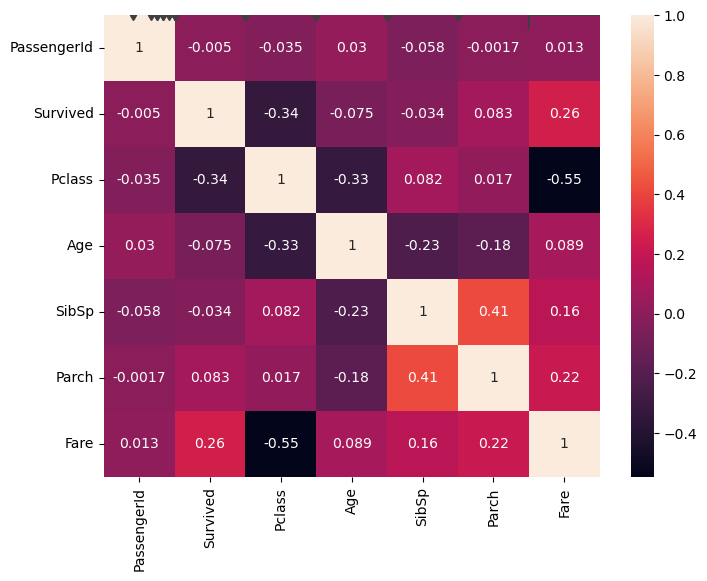

In [1476]:
corr=df.corr()
sns.heatmap(corr,annot=True)
plt.show()

In [1477]:
def correlation(df,threshold):
    cor=set()
    cor_matrix=df.corr()
    for i in range(len(cor_matrix.columns)):
        for j in range(i):
            if abs(cor_matrix.iloc[i,j])>threshold:
                colname=cor_matrix.columns[i]
                cor.add(colname)
    return cor
                

In [1478]:
cor_features=correlation(df,0.8)
print(len(cor_features))
cor_features

0


set()

In [1479]:
data

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000000,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000000,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000000,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000000,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.000000,0,0,373450,8.0500,S
...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.000000,0,0,211536,13.0000,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.000000,0,0,112053,30.0000,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,29.699118,1,2,W./C. 6607,23.4500,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.000000,0,0,111369,30.0000,C


In [1480]:
data['Gender']=data['Sex'].map({'male':0,'female':1})

In [1481]:
data

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Gender
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000000,1,0,A/5 21171,7.2500,S,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000000,1,0,PC 17599,71.2833,C,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000000,0,0,STON/O2. 3101282,7.9250,S,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000000,1,0,113803,53.1000,S,1
4,5,0,3,"Allen, Mr. William Henry",male,35.000000,0,0,373450,8.0500,S,0
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.000000,0,0,211536,13.0000,S,0
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.000000,0,0,112053,30.0000,S,1
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,29.699118,1,2,W./C. 6607,23.4500,S,1
889,890,1,1,"Behr, Mr. Karl Howell",male,26.000000,0,0,111369,30.0000,C,0


In [1482]:
data.drop(columns=['Name','Sex','Ticket','Embarked'],axis=1,inplace=True)

In [1483]:
data.shape

(889, 8)

In [1484]:
data

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Gender
0,1,0,3,22.000000,1,0,7.2500,0
1,2,1,1,38.000000,1,0,71.2833,1
2,3,1,3,26.000000,0,0,7.9250,1
3,4,1,1,35.000000,1,0,53.1000,1
4,5,0,3,35.000000,0,0,8.0500,0
...,...,...,...,...,...,...,...,...
886,887,0,2,27.000000,0,0,13.0000,0
887,888,1,1,19.000000,0,0,30.0000,1
888,889,0,3,29.699118,1,2,23.4500,1
889,890,1,1,26.000000,0,0,30.0000,0


In [1485]:
data.isna().sum()

PassengerId    0
Survived       0
Pclass         0
Age            0
SibSp          0
Parch          0
Fare           0
Gender         0
dtype: int64

In [1486]:
data.corr()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Gender
PassengerId,1.000000,-0.005028,-0.035330,0.030300,-0.057686,-0.001657,0.012703,-0.043136
Survived,-0.005028,1.000000,-0.335549,-0.074673,-0.034040,0.083151,0.255290,0.541585
Pclass,-0.035330,-0.335549,1.000000,-0.327954,0.081656,0.016824,-0.548193,-0.127741
Age,0.030300,-0.074673,-0.327954,1.000000,-0.231875,-0.178232,0.088604,-0.089434
SibSp,-0.057686,-0.034040,0.081656,-0.231875,1.000000,0.414542,0.160887,0.116348
Parch,-0.001657,0.083151,0.016824,-0.178232,0.414542,1.000000,0.217532,0.247508
Fare,0.012703,0.255290,-0.548193,0.088604,0.160887,0.217532,1.000000,0.179958
Gender,-0.043136,0.541585,-0.127741,-0.089434,0.116348,0.247508,0.179958,1.000000


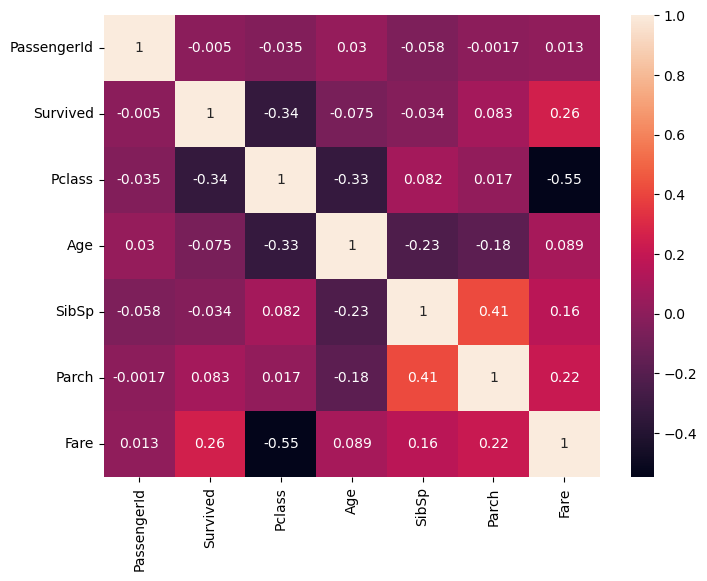

In [1487]:
sns.heatmap(corr,annot=True)
plt.show()

In [1488]:
cor_features=correlation(data,0.8)
print(len(cor_features))


0


In [1489]:
data.corr()['Survived'].sort_values(ascending=True)

Pclass        -0.335549
Age           -0.074673
SibSp         -0.034040
PassengerId   -0.005028
Parch          0.083151
Fare           0.255290
Gender         0.541585
Survived       1.000000
Name: Survived, dtype: float64

# Model Building

In [1490]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [1491]:
data.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare',
       'Gender'],
      dtype='object')

In [1492]:
X=data[['PassengerId', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare',
       'Gender']]

In [1493]:
y=data['Survived']

In [1494]:
X

,PassengerId,Pclass,Age,SibSp,Parch,Fare,Gender
0,1,3,22.000000,1,0,7.2500,0
1,2,1,38.000000,1,0,71.2833,1
2,3,3,26.000000,0,0,7.9250,1
3,4,1,35.000000,1,0,53.1000,1
4,5,3,35.000000,0,0,8.0500,0
...,...,...,...,...,...,...,...
886,887,2,27.000000,0,0,13.0000,0
887,888,1,19.000000,0,0,30.0000,1
888,889,3,29.699118,1,2,23.4500,1
889,890,1,26.000000,0,0,30.0000,0


In [1495]:
y

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 889, dtype: int64

# splitting dataset into train and test dataset

In [1496]:
X_train, X_test, y_train, y_test=train_test_split(X,y,random_state=0,test_size=0.33)

In [1497]:
X_train

,PassengerId,Pclass,Age,SibSp,Parch,Fare,Gender
171,172,3,4.000000,4,1,29.1250,0
188,189,3,40.000000,1,1,15.5000,0
799,800,3,30.000000,1,1,24.1500,1
433,434,3,17.000000,0,0,7.1250,0
651,652,2,18.000000,0,1,23.0000,1
...,...,...,...,...,...,...,...
837,838,3,29.699118,0,0,8.0500,0
193,194,2,3.000000,1,1,26.0000,0
630,631,1,80.000000,0,0,30.0000,0
560,561,3,29.699118,0,0,7.7500,0


In [1498]:
lr=LogisticRegression()
lr.fit(X_train,y_train)

LogisticRegression()

In [1499]:
y_train_pred=lr.predict(X_train)

In [1500]:
y_test_pred=lr.predict(X_test)

In [1501]:
len(y_train_pred),y_train_pred

(595,
 array([0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0,
        0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1,
        1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0,
        0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0,
        0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0,
        0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1,
        1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1,
        0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1,
        0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0,
        0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1,
        0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1,
        1, 0, 1, 0, 0, 0, 1, 1, 

In [1502]:
y_test

14     0
159    0
763    1
741    0
483    1
      ..
320    0
522    0
609    1
243    0
453    1
Name: Survived, Length: 294, dtype: int64

In [1503]:
y_test_pred

array([1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0,
       1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0,
       0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1,
       1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1,
       1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1,
       1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 1, 0, 0], dtype=int64)

In [1504]:
confusion_matrix(y_train,y_train_pred)

array([[333,  42],
       [ 68, 152]], dtype=int64)

In [1505]:
accuracy_score(y_train,y_train_pred)

0.8151260504201681

In [1506]:
precision_score(y_train,y_train_pred)

0.7835051546391752

In [1507]:
recall_score(y_train,y_train_pred)

0.6909090909090909

In [1508]:
print(classification_report(y_train,y_train_pred))

              precision    recall  f1-score   support

           0       0.83      0.89      0.86       375
           1       0.78      0.69      0.73       220

    accuracy                           0.82       595
   macro avg       0.81      0.79      0.80       595
weighted avg       0.81      0.82      0.81       595



TRAINING EVALUATION 0.2


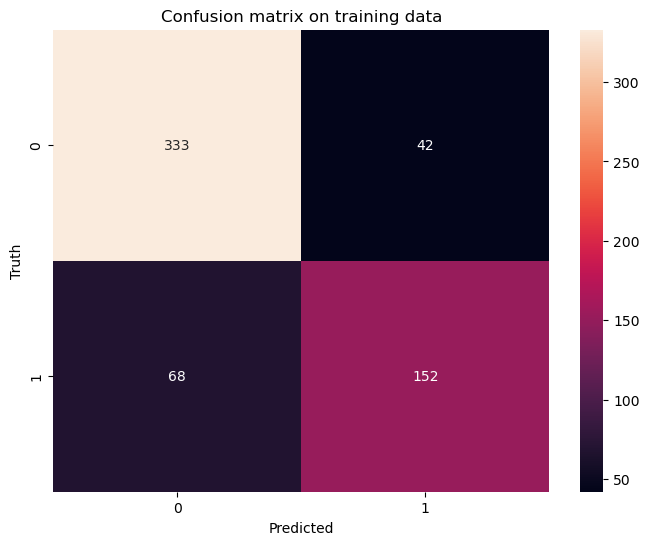

--------------------------------------
TP:152
F1-score:333
FP:42
FN:68
Accuracy:0.8151260504201681
Recall:0.6909090909090909
F1-score:0.7342995169082126
Precision:0.7835051546391752


In [1509]:
print("TRAINING EVALUATION 0.2")
sns.heatmap(confusion_matrix(y_train,y_train_pred),annot=True,fmt='d')
plt.title('Confusion matrix on training data')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.show()
print('--------------------------------------')
tn, fp, fn, tp=confusion_matrix(y_train,y_train_pred).ravel()
print('TP:{}'.format(tp))
print('F1-score:{}'.format(tn))
print('FP:{}'.format(fp))
print('FN:{}'.format(fn))
print('Accuracy:{}'.format((tp+tn)/(tp+tn+fp+fn)))
print('Recall:{}'.format(recall_score(y_train,y_train_pred)))
print('F1-score:{}'.format(f1_score(y_train,y_train_pred)))
print('Precision:{}'.format(precision_score(y_train,y_train_pred)))

In [ ]:
TP:138
F1-score:294
FP:39
FN:62
Accuracy:0.8105065666041276
Recall:0.69
F1-score:0.7320954907161803
Precision:0.7796610169491526

TEST EVALUATION 0.33
294 [1 0 1 0 0 0 0 0 1 0 1 1 1 0 1 0 1 1 0 1 0 1 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0
 0 0 0 1 0 1 0 1 0 0 0 0 0 1 0 0 1 0 1 1 1 0 0 1 0 1 0 0 0 1 1 0 1 0 0 0 1
 0 0 0 0 1 0 0 1 1 1 1 0 0 0 0 0 0 1 1 0 0 1 1 1 0 1 0 1 0 1 0 1 0 0 0 1 1
 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 1 1 0 0 0 1 0 1 0 1 1
 0 0 0 0 1 0 0 0 1 1 1 0 0 0 1 0 0 1 0 1 0 1 0 0 0 0 0 0 0 1 0 1 0 1 1 0 0
 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 1 1 1 0 1 1 0 1 0 0 1 1 0 1 1 0 1 0 0 1 1 0
 1 1 0 1 0 0 1 1 1 0 0 1 0 1 0 0 0 0 0 1 1 1 0 0 0 0 1 1 0 0 1 0 1 1 0 0 0
 0 1 1 0 0 0 0 1 0 0 1 1 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 1 0 0]
              precision    recall  f1-score   support

           0       0.78      0.85      0.82       174
           1       0.75      0.66      0.70       120

    accuracy                           0.77       294
   macro avg       0.77      0.75      0.76       294
weighted avg       0.77      0.77      0.77       294



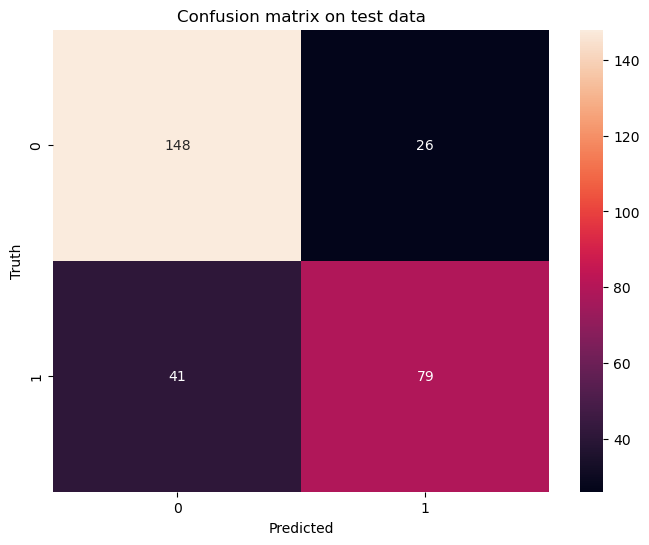

--------------------------------------
TP:152
F1-score:333
FP:42
FN:68
Accuracy:0.8151260504201681
Recall:0.6583333333333333
F1-score:0.7022222222222223
Precision:0.7523809523809524


In [1510]:
# y_test_pred=lr.predict(X_test)
print("TEST EVALUATION 0.33")
y_test_pred=lr.predict(X_test)

print(len(y_test_pred),y_test_pred)

y_test

y_test_pred

confusion_matrix(y_test,y_test_pred)

accuracy_score(y_test,y_test_pred)

precision_score(y_test,y_test_pred)

recall_score(y_test,y_test_pred)

print(classification_report(y_test,y_test_pred))

sns.heatmap(confusion_matrix(y_test,y_test_pred),annot=True,fmt='d')
plt.title('Confusion matrix on test data')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.show()
print('--------------------------------------')
ttn, ftp, ftn, ttp=confusion_matrix(y_test,y_test_pred).ravel()
print('TP:{}'.format(tp))
print('F1-score:{}'.format(tn))
print('FP:{}'.format(fp))
print('FN:{}'.format(fn))
print('Accuracy:{}'.format((tp+tn)/(tp+tn+fp+fn)))
print('Recall:{}'.format(recall_score(y_test,y_test_pred)))
print('F1-score:{}'.format(f1_score(y_test,y_test_pred)))
print('Precision:{}'.format(precision_score(y_test,y_test_pred)))

TEST EVALUATION 0.4
356 [1 0 1 0 0 0 0 0 1 0 1 1 1 0 1 0 1 0 0 1 0 1 0 0 0 0 1 0 0 0 0 0 0 1 0 0 0
 0 0 0 1 0 1 0 1 0 0 0 0 0 1 0 0 1 0 1 1 1 0 0 1 0 1 0 0 0 1 1 0 1 0 0 0 1
 0 0 0 0 1 0 0 1 1 1 1 0 0 0 0 0 0 1 1 0 0 1 1 1 0 1 0 1 0 1 0 1 0 0 0 1 1
 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 1 1 0 0 0 1 0 1 0 1 1
 0 0 0 0 1 0 0 0 1 1 1 0 0 0 1 0 0 1 0 1 0 1 0 0 0 0 0 0 0 1 0 1 0 1 1 0 0
 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 1 1 1 0 1 1 0 1 0 0 1 1 0 1 1 0 1 0 0 1 1 0
 1 1 0 1 0 0 1 1 1 0 0 1 0 1 0 0 0 0 0 1 1 1 0 0 0 0 1 1 0 0 1 0 1 1 0 0 0
 0 1 1 0 0 0 0 1 0 0 1 1 1 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 1 0 0 1 0 0 0 0
 1 0 1 0 1 1 1 0 0 0 1 0 0 0 1 0 0 0 1 0 0 0 0 1 1 0 0 0 1 0 0 1 1 0 0 0 0
 0 0 0 1 1 1 1 1 0 0 0 1 1 1 0 0 1 0 0 1 0 0 0]
              precision    recall  f1-score   support

           0       0.80      0.84      0.82       216
           1       0.74      0.68      0.71       140

    accuracy                           0.78       356
   macro avg       0.77      0.76  

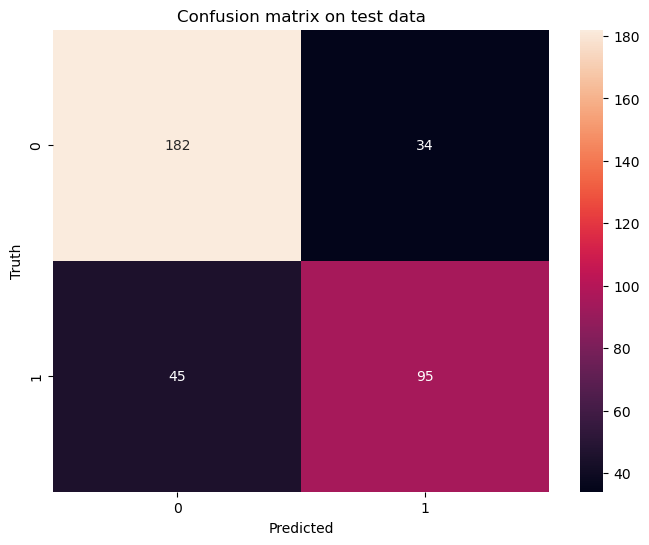

--------------------------------------
TP:138
F1-score:294
FP:39
FN:62
Accuracy:0.8105065666041276
Recall:0.6785714285714286
F1-score:0.7063197026022305
Precision:0.7364341085271318


In [1330]:
# y_test_pred=lr.predict(X_test)
print("TEST EVALUATION 0.4")
y_test_pred=lr.predict(X_test)

print(len(y_test_pred),y_test_pred)

y_test

y_test_pred

confusion_matrix(y_test,y_test_pred)

accuracy_score(y_test,y_test_pred)

precision_score(y_test,y_test_pred)

recall_score(y_test,y_test_pred)

print(classification_report(y_test,y_test_pred))

sns.heatmap(confusion_matrix(y_test,y_test_pred),annot=True,fmt='d')
plt.title('Confusion matrix on test data')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.show()
print('--------------------------------------')
ttn, ftp, ftn, ttp=confusion_matrix(y_test,y_test_pred).ravel()
print('TP:{}'.format(tp))
print('F1-score:{}'.format(tn))
print('FP:{}'.format(fp))
print('FN:{}'.format(fn))
print('Accuracy:{}'.format((tp+tn)/(tp+tn+fp+fn)))
print('Recall:{}'.format(recall_score(y_test,y_test_pred)))
print('F1-score:{}'.format(f1_score(y_test,y_test_pred)))
print('Precision:{}'.format(precision_score(y_test,y_test_pred)))

In [1331]:
y_train_pred=lr.predict(X_train)

In [1332]:
y_test_pred=lr.predict(X_test)

In [1333]:
len(y_train_pred),y_train_pred

(533,
 array([1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1,
        0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1,
        0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0,
        1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1,
        1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
        1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0,
        1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0,
        0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0,
        0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0,
        0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1,
        1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0,
        1, 1, 0, 0, 1, 0, 0, 0, 

In [1334]:
y_test

14     0
159    0
763    1
741    0
483    1
      ..
839    1
820    1
101    0
704    0
739    0
Name: Survived, Length: 356, dtype: int64

In [1335]:
y_test_pred

array([1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0,
       1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0,
       0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1,
       1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1,
       1, 0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1,
       1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1,

In [1336]:
confusion_matrix(y_train,y_train_pred)

array([[294,  39],
       [ 62, 138]], dtype=int64)

In [1337]:
accuracy_score(y_train,y_train_pred)

0.8105065666041276

In [1338]:
precision_score(y_train,y_train_pred)

0.7796610169491526

In [1339]:
recall_score(y_train,y_train_pred)

0.69

In [1340]:
print(classification_report(y_train,y_train_pred))

              precision    recall  f1-score   support

           0       0.83      0.88      0.85       333
           1       0.78      0.69      0.73       200

    accuracy                           0.81       533
   macro avg       0.80      0.79      0.79       533
weighted avg       0.81      0.81      0.81       533



TRAINING EVALUATION 0.4


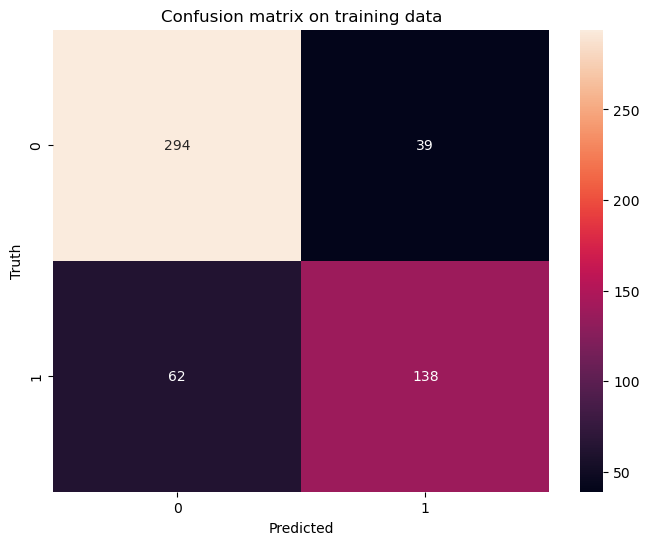

--------------------------------------
TP:138
F1-score:294
FP:39
FN:62
Accuracy:0.8105065666041276
Recall:0.69
F1-score:0.7320954907161803
Precision:0.7796610169491526


In [1341]:
print("TRAINING EVALUATION 0.4")
sns.heatmap(confusion_matrix(y_train,y_train_pred),annot=True,fmt='d')
plt.title('Confusion matrix on training data')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.show()

print('--------------------------------------')
tn, fp, fn, tp=confusion_matrix(y_train,y_train_pred).ravel()
print('TP:{}'.format(tp))
print('F1-score:{}'.format(tn))
print('FP:{}'.format(fp))
print('FN:{}'.format(fn))
print('Accuracy:{}'.format((tp+tn)/(tp+tn+fp+fn)))
print('Recall:{}'.format(recall_score(y_train,y_train_pred)))
print('F1-score:{}'.format(f1_score(y_train,y_train_pred)))
print('Precision:{}'.format(precision_score(y_train,y_train_pred)))

# Need to improve model performance using Hyperparameter Tuning

In [1511]:
data

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare,Gender
0,1,0,3,22.000000,1,0,7.2500,0
1,2,1,1,38.000000,1,0,71.2833,1
2,3,1,3,26.000000,0,0,7.9250,1
3,4,1,1,35.000000,1,0,53.1000,1
4,5,0,3,35.000000,0,0,8.0500,0
...,...,...,...,...,...,...,...,...
886,887,0,2,27.000000,0,0,13.0000,0
887,888,1,1,19.000000,0,0,30.0000,1
888,889,0,3,29.699118,1,2,23.4500,1
889,890,1,1,26.000000,0,0,30.0000,0


In [1513]:
data.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare',
       'Gender'],
      dtype='object')

In [1516]:
X=data[['PassengerId', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare',
       'Gender']]

In [1517]:
y=data['Survived']

In [1518]:
X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [1519]:
X_train.shape, X_test.shape

((711, 7), (178, 7))

In [1521]:
hyperparameters={
    'penalty':['l1','l2','elasticnet'],
    'solver':['newton-cg','lbfgs','liblinear'],
    'C':[1.0,0.1,0.01],
    'max_iter':[100,200,500,1000]
}
hyperparameters

{'penalty': ['l1', 'l2', 'elasticnet'],
 'solver': ['newton-cg', 'lbfgs', 'liblinear'],
 'C': [1.0, 0.1, 0.01],
 'max_iter': [100, 200, 500, 1000]}

In [1522]:
from sklearn.model_selection import GridSearchCV

In [1524]:
classifier=LogisticRegression()
grid_search=GridSearchCV(classifier,hyperparameters,cv=5)
grid_search.fit(X_train,y_train)

GridSearchCV(cv=5, estimator=LogisticRegression(),
             param_grid={'C': [1.0, 0.1, 0.01],
                         'max_iter': [100, 200, 500, 1000],
                         'penalty': ['l1', 'l2', 'elasticnet'],
                         'solver': ['newton-cg', 'lbfgs', 'liblinear']})

In [1527]:
grid_search.best_params_

{'C': 0.1, 'max_iter': 100, 'penalty': 'l2', 'solver': 'newton-cg'}

In [1528]:
grid_search.best_estimator_

LogisticRegression(C=0.1, solver='newton-cg')

In [1529]:
grid_search.best_score_

0.7988377819363734

In [1537]:
# print the best hyperparameters and the corresponding accuracy_score
print("Best Hyperparameters: ",grid_search.best_params_)
print("Best Accuracy Score: ",grid_search.best_score_)
print('\n')

# Evaluate the model with the best hyperparameters on the train set
best_classifier=grid_search.best_estimator_
y_train_pred=best_classifier.predict(X_train)
accuracy=accuracy_score(y_train,y_train_pred)
print("Train Accuracy: ",accuracy)

# Evaluate the model with the best hyperparameters on the test set
best_classifier=grid_search.best_estimator_
y_test_pred=best_classifier.predict(X_test)
accuracy=accuracy_score(y_test,y_test_pred)
print("Test Accuracy: ",accuracy)

Best Hyperparameters:  {'C': 0.1, 'max_iter': 100, 'penalty': 'l2', 'solver': 'newton-cg'}
Best Accuracy Score:  0.7988377819363734


Train Accuracy:  0.7974683544303798
Test Accuracy:  0.8089887640449438


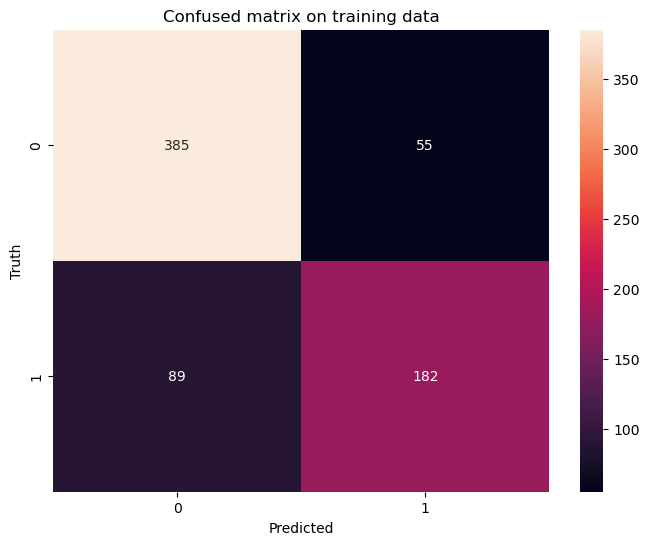

--------------------------------------------
TP:182
F1-score:385
FP:55
FN:89
Accuracy:0.7974683544303798
Recall:0.6715867158671587
F1-score:0.7165354330708662
Precision:0.7679324894514767


In [1544]:
# on training data
sns.heatmap(confusion_matrix(y_train,y_train_pred),annot=True,fmt='d')
plt.title('Confused matrix on training data')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.show()
print('--------------------------------------------')
tn,fp,fn,tp=confusion_matrix(y_train,y_train_pred).ravel()
print('TP:{}'.format(tp))
print('F1-score:{}'.format(tn))
print('FP:{}'.format(fp))
print('FN:{}'.format(fn))
print('Accuracy:{}'.format((tp+tn)/(tp+tn+fp+fn)))
print('Recall:{}'.format(recall_score(y_train,y_train_pred)))
print('F1-score:{}'.format(f1_score(y_train,y_train_pred)))
print('Precision:{}'.format(precision_score(y_train,y_train_pred)))

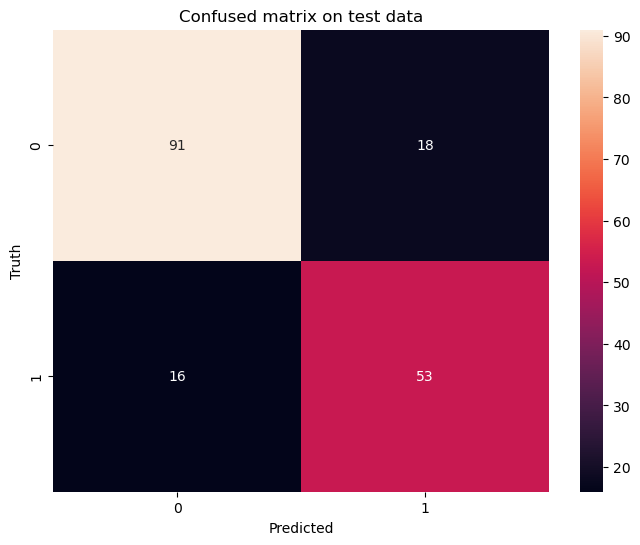

--------------------------------------------
TP:53
F1-score:91
FP:18
FN:16
Accuracy:0.8089887640449438
Recall:0.7681159420289855
F1-score:0.7571428571428571
Precision:0.7464788732394366


In [1545]:
# on test data
sns.heatmap(confusion_matrix(y_test,y_test_pred),annot=True,fmt='d')
plt.title('Confused matrix on test data')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.show()
print('--------------------------------------------')
tn,fp,fn,tp=confusion_matrix(y_test,y_test_pred).ravel()
print('TP:{}'.format(tp))
print('F1-score:{}'.format(tn))
print('FP:{}'.format(fp))
print('FN:{}'.format(fn))
print('Accuracy:{}'.format((tp+tn)/(tp+tn+fp+fn)))
print('Recall:{}'.format(recall_score(y_test,y_test_pred)))
print('F1-score:{}'.format(f1_score(y_test,y_test_pred)))
print('Precision:{}'.format(precision_score(y_test,y_test_pred)))